<a href="https://colab.research.google.com/github/24cs142-prog/24cs142-cat-2/blob/main/daily_climate_time_series_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install pandas numpy requests scikit-learn tensorflow matplotlib

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from google.colab import files

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0


In [8]:
import os

print("Please upload 'DailyDelhiClimateTrain.csv' and 'DailyDelhiClimateTest.csv'")
uploaded = files.upload()

# Helper to find the latest uploaded filename even if Google Colab auto-renamed it (e.g., adding '(1)')
def get_latest_file(default_name):
    if os.path.exists(default_name):
        return default_name
    # Look for renamed versions like 'DailyDelhiClimateTrain (1).csv'
    base, ext = os.path.splitext(default_name)
    candidates = [f for f in os.listdir('.') if f.startswith(base) and f.endswith(ext)]
    if candidates:
        # Sort to get the most recent copy
        return sorted(candidates)[-1]
    return default_name

train_path = get_latest_file("DailyDelhiClimateTrain.csv")
test_path = get_latest_file("DailyDelhiClimateTest.csv")

if not os.path.exists(train_path):
    print(f"Error: '{train_path}' is still missing. Please run this cell again and make sure to select and upload it.")
elif not os.path.exists(test_path):
    print(f"Error: '{test_path}' is still missing. Please run this cell again and make sure to select and upload it.")
else:
    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)
    print("Training dataset shape:", train_df.shape)
    print("Testing dataset shape:", test_df.shape)
    display(train_df.head())

Please upload 'DailyDelhiClimateTrain.csv' and 'DailyDelhiClimateTest.csv'


Saving DailyDelhiClimateTrain.csv to DailyDelhiClimateTrain.csv
Training dataset shape: (1462, 5)
Testing dataset shape: (114, 5)


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [9]:
for df in [train_df, test_df]:
    df["date"] = pd.to_datetime(df["date"])
    df.sort_values("date", inplace=True)
    df.drop_duplicates(subset="date", keep="last", inplace=True)

features = [
    "meantemp",
    "humidity",
    "wind_speed",
    "meanpressure"
]

for df in [train_df, test_df]:
    df[features] = df[features].apply(
        pd.to_numeric, errors="coerce"
    )

train_df[features] = train_df[features].interpolate(
    limit_direction="both"
)
test_df[features] = test_df[features].interpolate(
    limit_direction="both"
)

train_df = train_df.dropna(subset=features)
test_df = test_df.dropna(subset=features)

print("Missing values in training data:")
print(train_df[features].isnull().sum())

print("Training records:", len(train_df))
print("First date:", train_df["date"].min().date())
print("Last date:", train_df["date"].max().date())

Missing values in training data:
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64
Training records: 1462
First date: 2013-01-01
Last date: 2017-01-01


In [10]:
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_df[features])

test_scaled = scaler.transform(test_df[features])

print("Normalized training shape:", train_scaled.shape)
print("Normalized testing shape:", test_scaled.shape)
print("Minimum normalized value:", train_scaled.min())
print("Maximum normalized value:", train_scaled.max())

Normalized training shape: (1462, 4)
Normalized testing shape: (114, 4)
Minimum normalized value: 0.0
Maximum normalized value: 1.0


In [11]:
SEQ_LENGTH = 30
TEMP_INDEX = features.index("meantemp")

# Combine training and testing only to provide
# historical context for the test sequences.
all_scaled = np.vstack([train_scaled, test_scaled])

def create_sequences(data, target_start, target_end):
    X, y = [], []

    for target_idx in range(target_start, target_end):
        X.append(data[target_idx - SEQ_LENGTH:target_idx])
        y.append(data[target_idx, TEMP_INDEX])

    return np.array(X), np.array(y)

X_train, y_train = create_sequences(
    train_scaled, SEQ_LENGTH, len(train_scaled)
)

X_test, y_test = create_sequences(
    all_scaled,
    len(train_scaled),
    len(train_scaled) + len(test_scaled)
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1432, 30, 4)
y_train shape: (1432,)
X_test shape: (114, 30, 4)
y_test shape: (114,)


In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential([
    tf.keras.Input(shape=(SEQ_LENGTH, len(features))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=40,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM training completed!")

Epoch 1/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - loss: 0.0557 - val_loss: 0.0066
Epoch 2/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0067 - val_loss: 0.0080
Epoch 3/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0082 - val_loss: 0.0087
Epoch 4/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0080 - val_loss: 0.0087
Epoch 5/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0081 - val_loss: 0.0093
Epoch 6/40
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0080 - val_loss: 0.0088
LSTM training completed!


In [14]:
pred_scaled = model.predict(X_test, verbose=0).flatten()

temp_min = scaler.data_min_[TEMP_INDEX]
temp_range = scaler.data_range_[TEMP_INDEX]

actual_temp = y_test * temp_range + temp_min
predicted_temp = pred_scaled * temp_range + temp_min

mae = mean_absolute_error(actual_temp, predicted_temp)
rmse = np.sqrt(mean_squared_error(actual_temp, predicted_temp))

print("MAE:", round(mae, 3), "°C")
print("RMSE:", round(rmse, 3), "°C")

MAE: 2.406 °C
RMSE: 2.79 °C


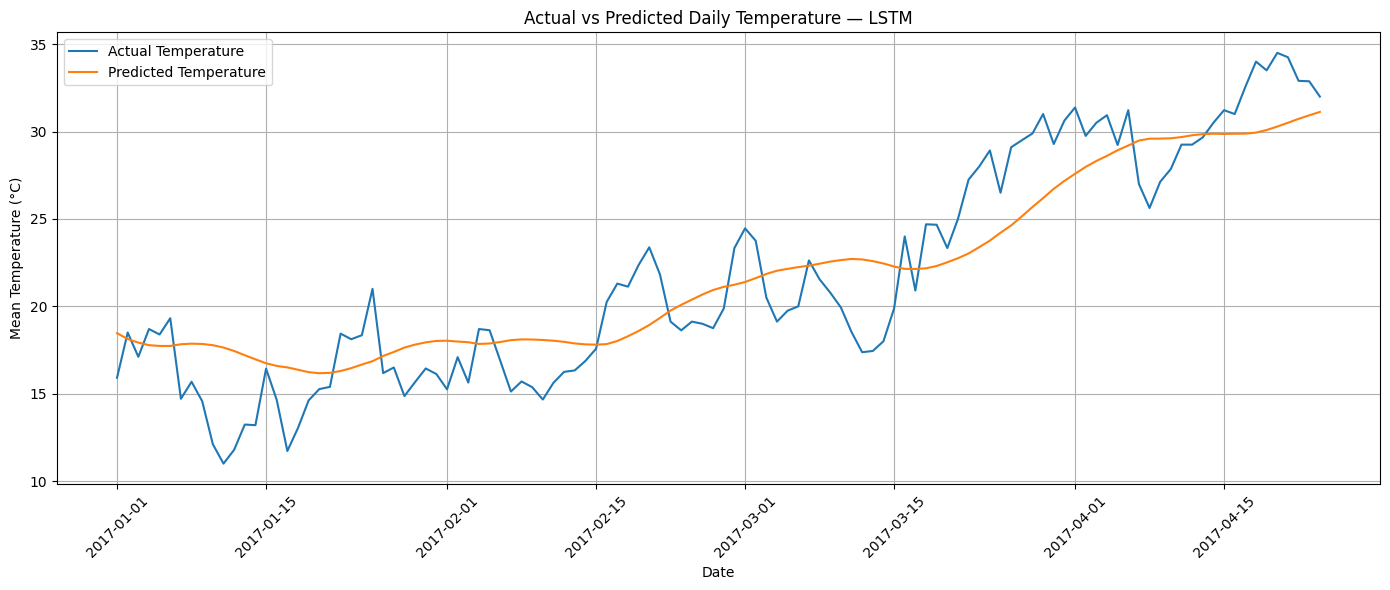

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_df["date"].iloc[:len(actual_temp)],
    actual_temp,
    label="Actual Temperature"
)

plt.plot(
    test_df["date"].iloc[:len(predicted_temp)],
    predicted_temp,
    label="Predicted Temperature"
)

plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.title("Actual vs Predicted Daily Temperature — LSTM")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
# Start with the last 30 observed days
current_sequence = all_scaled[-SEQ_LENGTH:].copy()

future_predictions = []

for i in range(7):
    # Predict next day's normalized temperature
    next_scaled_temp = model.predict(
        current_sequence[np.newaxis, :, :],
        verbose=0
    )[0, 0]

    # Convert temperature to Celsius
    next_temp = next_scaled_temp * temp_range + temp_min
    future_predictions.append(next_temp)

    # Create next row using the latest weather features
    next_row = current_sequence[-1].copy()
    next_row[TEMP_INDEX] = next_scaled_temp

    # Move the sequence forward by one day
    current_sequence = np.vstack([
        current_sequence[1:],
        next_row
    ])

future_dates = pd.date_range(
    start=test_df["date"].max() + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted Temperature (°C)": np.round(
        future_predictions, 2
    )
})

display(forecast_df)

,Date,Predicted Temperature (°C)
0,2017-04-25,31.30
1,2017-04-26,31.44
2,2017-04-27,31.56
3,2017-04-28,31.66
4,2017-04-29,31.74
5,2017-04-30,31.80
6,2017-05-01,31.86


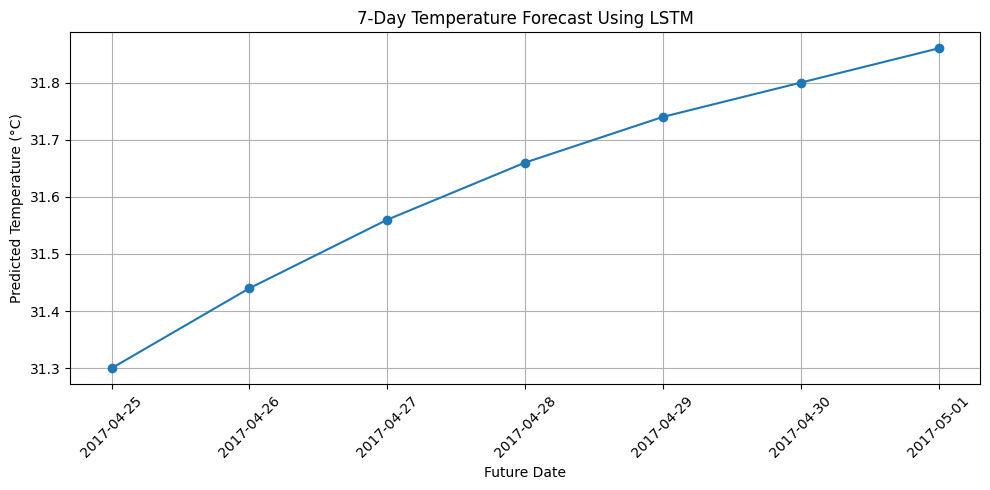

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(
    forecast_df["Date"],
    forecast_df["Predicted Temperature (°C)"],
    marker="o"
)

plt.xlabel("Future Date")
plt.ylabel("Predicted Temperature (°C)")
plt.title("7-Day Temperature Forecast Using LSTM")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()